# A likelihood under cobaya: DESI DR2 BAO

This notebook samples a cosmological posterior with [cobaya](https://cobaya.readthedocs.io), with this package as the theory.
The data are the DESI DR2 BAO distances {cite:p}`AbdulKarimAguilarAhlen_2025PhRvD.112h3515A`, and the model is flat $\Lambda$CDM with a BBN prior on $\omega_b$.

It has two parts.

1. cobaya's own DESI likelihood, `bao.desi_dr2.desi_bao_all`, with `ggah_mod.interfaces.cobaya.GgahMod` as its `Theory`: one evaluation, then a Markov chain.
2. The same likelihood written with this package in JAX and handed to cobaya as an external `Likelihood`: its $\chi^2$ against cobaya's, the Fisher matrix from its exact gradient, and a minimisation.

The first part is what a user of cobaya's likelihoods needs; the second is the pattern for a likelihood of one's own, such as the $w_p$ fit of {doc}`fit_wp`.

It needs the `cobaya` extra, `pip install "ggah_mod[cobaya]"`, and cobaya's BAO data, which the second cell installs on first use (a clone of `CobayaSampler/bao_data`, a few MB).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import pathlib
import tempfile
import warnings

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from cobaya.install import install
from cobaya.likelihood import Likelihood
from cobaya.model import get_model
from cobaya.run import run
from getdist import MCSamples, plots
from getdist.gaussian_mixtures import GaussianND

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)
from ggah_mod.cosmology import r_drag
from ggah_mod.cosmology.background import comoving_distance, hubble_e, transverse_distance

PACKAGES = os.environ.get("COBAYA_PACKAGES_PATH",
                          str(pathlib.Path.home() / ".cache" / "ggah_mod" / "cobaya_packages"))
BAO = pathlib.Path(PACKAGES) / "data" / "bao_data" / "desi_bao_dr2"
if not BAO.is_dir():
    install({"likelihood": {"bao.desi_dr2.desi_bao_all": None}}, path=PACKAGES)
print("cobaya packages in", PACKAGES)

cobaya packages in /home/jcomparat/data/cobaya_packages


## The model

A cobaya run is one dictionary: a theory, the likelihoods, the parameters, and a sampler.

- **Theory**: `GgahMod` in the `differentiable` flavour, with `emu_pk` for the spectrum.
  BAO needs only the background and the sound horizon $r_d$, so the spectrum is never evaluated here.
  The neutrino mass, $\sum m_\nu = 0.06$ eV, is split into three equal masses, as DESI does.
- **Parameters**: cobaya's spelling, $H_0$, $\omega_b = \Omega_bh^2$ and $\omega_c = \Omega_ch^2$.
  The theory converts them to this package's, in which $\Omega_m$ contains the massive neutrinos (see `ggah_mod.interfaces.cobaya`).
  $n_s$ and $\ln(10^{10}A_s)$ are fixed: BAO does not see them.
- **Priors**: uniform on $H_0$ and $\omega_c$, and the BBN prior $\omega_b = 0.02218 \pm 0.00055$ {cite:p}`Schoneberg_2024JCAP...06..006S`, the one of DESI's `schoneberg2024-bbn` chains.
- **Derived**: $\Omega_m$ and $r_d$ in Mpc, which the theory provides.

In [2]:
THEORY = {"ggah_mod.interfaces.cobaya.GgahMod": {
    "backend": "differentiable", "pk": "emu_pk", "nu_hierarchy": "degenerate"}}
BBN = (0.02218, 0.00055)
PARAMS = {
    "H0": {"prior": {"min": 55.0, "max": 80.0}, "ref": {"dist": "norm", "loc": 67.7, "scale": 0.5},
           "proposal": 0.5, "latex": r"H_0"},
    "ombh2": {"prior": {"dist": "norm", "loc": BBN[0], "scale": BBN[1]},
              "ref": {"dist": "norm", "loc": 0.0222, "scale": 0.0003}, "proposal": 0.0003, "latex": r"\omega_b"},
    "omch2": {"prior": {"min": 0.08, "max": 0.16}, "ref": {"dist": "norm", "loc": 0.119, "scale": 0.002},
              "proposal": 0.002, "latex": r"\omega_c"},
    "ns": 0.9649, "logA": 3.044, "mnu": 0.06,
    "Omega_m": {"latex": r"\Omega_m"},
    "rdrag": {"latex": r"r_d"},
}
info = {"packages_path": PACKAGES, "theory": THEORY, "params": PARAMS,
        "likelihood": {"bao.desi_dr2.desi_bao_all": None}}

## One evaluation

`get_model` builds the model without a sampler, which is how to check a set-up before running a chain.
The log-posterior is the sum of the log-prior and the log-likelihood, $-\chi^2/2$ for a Gaussian likelihood.

In [3]:
model = get_model(info)
point = {"H0": 67.66, "ombh2": 0.02242, "omch2": 0.11933}     # Planck 2018
res = model.logposterior(point, as_dict=True)
like = model.likelihood["bao.desi_dr2.desi_bao_all"]
chi2_cobaya = res["derived"]["chi2__BAO"]
print(f"chi^2 = {chi2_cobaya:.3f} for {len(like.data)} measurements")
print(f"r_d   = {res['derived']['rdrag']:.3f} Mpc,  Omega_m = {res['derived']['Omega_m']:.5f}")

[bao.desi_dr2.desi_bao_all] Initialized.


chi^2 = 22.515 for 13 measurements
r_d   = 147.234 Mpc,  Omega_m = 0.31105


The likelihood asks the theory for $H(z)$, $D_A(z)$ and $r_d$, and forms the ratios DESI measures.
Each one against its measurement:

In [4]:
for (_, row) in like.data.iterrows():
    t = float(np.ravel(like.theory_fun(row["z"], row["observable"]))[0])
    print(f"z = {row['z']:5.3f}  {row['observable']:11s}  model {t:7.3f}   DESI {row['value']:7.3f}")

z = 0.295  DV_over_rs   model   8.023   DESI   7.942
z = 0.510  DM_over_rs   model  13.448   DESI  13.588
z = 0.510  DH_over_rs   model  22.684   DESI  21.863
z = 0.706  DM_over_rs   model  17.639   DESI  17.351
z = 0.706  DH_over_rs   model  20.135   DESI  19.455
z = 0.934  DM_over_rs   model  21.928   DESI  21.576
z = 0.934  DH_over_rs   model  17.552   DESI  17.641
z = 1.321  DM_over_rs   model  28.011   DESI  27.601
z = 1.321  DH_over_rs   model  14.063   DESI  14.176
z = 1.484  DM_over_rs   model  30.205   DESI  30.512
z = 1.484  DH_over_rs   model  12.881   DESI  12.817
z = 2.330  DH_over_rs   model   8.622   DESI   8.632
z = 2.330  DM_over_rs   model  39.116   DESI  38.989


## The chain

cobaya's `mcmc` sampler is a Metropolis sampler that learns its proposal covariance as it goes, and stops when the Gelman–Rubin $R-1$ of the means falls below `Rminus1_stop`.
With one process the test splits the chain into four parts.
An evaluation takes about 15 ms, so the chain converges in under a minute.

In [5]:
out = tempfile.mkdtemp()
_, sampler = run(dict(info, sampler={"mcmc": {"Rminus1_stop": 0.01, "max_tries": 1000}},
                      output=f"{out}/bao", force=True))
chain = sampler.products(to_getdist=True, skip_samples=0.3)["sample"]
for p in ("H0", "Omega_m", "ombh2", "rdrag"):
    print(f"{p:8s} = {chain.mean(p):.4f} +- {chain.std(p):.4f}")
# DESI DR2 (Abdul Karim et al. 2025), flat LCDM, BAO alone and BAO + BBN
assert abs(chain.mean("Omega_m") - 0.2975) < 0.2 * 0.0086
assert abs(chain.mean("H0") - 68.51) < 0.2 * 0.58

[output] Output to be read-from/written-into folder '/tmp/tmp2nr7g9lc', with prefix 'bao'


[bao.desi_dr2.desi_bao_all] Initialized.


[mcmc] Getting initial point... (this may take a few seconds)


[mcmc] Initial point: H0:68.20432, ombh2:0.02180674, omch2:0.1137638


[model] Measuring speeds... (this may take a few seconds)


[model] Setting measured speeds (per sec): {bao.desi_dr2.desi_bao_all: 691.0, ggah_mod.interfaces.cobaya.GgahMod: 517.0}


... (91 outputs left out)

[mcmc] The run has converged!


[mcmc] Sampling complete after 2640 accepted steps.


[root] *WARNING* outlier fraction 0.016774891774891776 


H0       = 68.5302 +- 0.5888
Omega_m  = 0.2977 +- 0.0090
ombh2    = 0.0222 +- 0.0005
rdrag    = 148.1551 +- 1.6320


DESI DR2 quotes $\Omega_m = 0.2975 \pm 0.0086$ and, with BBN, $H_0 = 68.51 \pm 0.58$ km s$^{-1}$ Mpc$^{-1}$ {cite:p}`AbdulKarimAguilarAhlen_2025PhRvD.112h3515A`; the chain reproduces both to a fraction of their errors.

## A likelihood of one's own, in JAX

cobaya's likelihood is a black box to JAX: it calls the theory through numpy, so its gradient is not available.
The same $\chi^2$ written with this package's functions is differentiable end to end:

$$\chi^2(\theta) = [\boldsymbol d - \boldsymbol t(\theta)]^{\rm T}\,\mathsf C^{-1}\,[\boldsymbol d - \boldsymbol t(\theta)],$$

with $\boldsymbol t$ the ratios $D_M/r_d$, $D_H/r_d$ and $D_V/r_d$, where $D_M = f_K(\chi)$, $D_H = c/H(z)$ and $D_V = (zD_M^2D_H)^{1/3}$.
All three distances and $r_d$ are in $h^{-1}$Mpc, so the ratios carry no unit.
The data vector and covariance are the files cobaya's likelihood reads.

In [6]:
data = np.genfromtxt(BAO / "desi_gaussian_bao_ALL_GCcomb_mean.txt", dtype=None, encoding=None,
                     names=("z", "value", "observable"))
Z = jnp.asarray(data["z"])
D = jnp.asarray(data["value"])
CINV = jnp.asarray(np.linalg.inv(np.loadtxt(BAO / "desi_gaussian_bao_ALL_GCcomb_cov.txt")))
KIND = {"DV_over_rs": 0, "DM_over_rs": 1, "DH_over_rs": 2}
IDX = jnp.asarray([KIND[o] for o in data["observable"]])


def bao_vector(cosmo):
    """D_V/r_d, D_M/r_d or D_H/r_d at each measurement, as DESI orders them."""
    rd = r_drag(cosmo)
    dm = transverse_distance(comoving_distance(Z, cosmo), cosmo)
    dh = cosmo.hubble_distance / hubble_e(Z, cosmo)
    dv = jnp.cbrt(Z * dm ** 2 * dh)
    return jnp.stack([dv, dm, dh])[IDX, jnp.arange(Z.size)] / rd


@jax.jit
def chi2_bao(cosmo):
    r = D - bao_vector(cosmo)
    return r @ CINV @ r

As a cobaya `Likelihood` it is three methods.
`get_requirements` asks the theory for the `Cosmology` itself, which `GgahMod` provides as `ggah_cosmology`; `logp` returns $-\chi^2/2$.

In [7]:
class DesiBaoJax(Likelihood):
    """DESI DR2 BAO, computed with ggah_mod in JAX."""

    def get_requirements(self):
        return {"ggah_cosmology": None}

    def logp(self, **params):
        return -0.5 * float(chi2_bao(self.provider.get_ggah_cosmology()))


info_jax = dict(info, likelihood={"desi_bao_jax": {"external": DesiBaoJax}})
model_jax = get_model(info_jax)
chi2_jax = -2 * model_jax.logposterior(point, as_dict=True)["loglikes"]["desi_bao_jax"]
print(f"chi^2: cobaya's likelihood {chi2_cobaya:.6f}, this one {chi2_jax:.6f}")
assert abs(chi2_jax - chi2_cobaya) < 1e-6 * chi2_cobaya

chi^2: cobaya's likelihood 22.515388, this one 22.515388


The two agree to the last digit printed: they read the same files and the same theory.

## The Fisher matrix

With the gradient, the Fisher matrix of the Gaussian likelihood is $\mathsf F = \mathsf J^{\rm T}\mathsf C^{-1}\mathsf J$, with $\mathsf J = \partial\boldsymbol t/\partial\theta$ from automatic differentiation, plus the BBN prior.
Here $\theta = (\Omega_m, \Omega_b, h)$, the fields of the `Cosmology`; $\omega_b = \Omega_bh^2$, so the prior adds $\boldsymbol g\boldsymbol g^{\rm T}/\sigma_{\omega_b}^2$ with $\boldsymbol g = \partial\omega_b/\partial\theta = (0, h^2, 2\Omega_bh)$.
It is evaluated at the mean of the chain.

In [8]:
FID = model_jax.provider.get_ggah_cosmology()
mean = {p: chain.mean(p) for p in ("H0", "ombh2", "omch2")}
model_jax.logposterior(mean)
c0 = model_jax.provider.get_ggah_cosmology()
P = ("Omega_m", "Omega_b", "h")
t0 = np.array([float(getattr(c0, p)) for p in P])

J = np.asarray(jax.jacfwd(lambda t: bao_vector(c0.replace(**dict(zip(P, t)))))(jnp.asarray(t0)))
g = np.array([0.0, t0[2] ** 2, 2 * t0[1] * t0[2]])
F = J.T @ np.asarray(CINV) @ J + np.outer(g, g) / BBN[1] ** 2
cov_f = np.linalg.inv(F)
for p, x, s in zip(P, t0, np.sqrt(np.diag(cov_f))):
    print(f"{p:8s} {x:.4f} +- {s:.4f}   (Fisher)")

Omega_m  0.2978 +- 0.0086   (Fisher)
Omega_b  0.0472 +- 0.0008   (Fisher)
h        0.6853 +- 0.0060   (Fisher)


The chain records $\Omega_m$ and $H_0$; $\Omega_b$ is derived from them as $\omega_b/h^2$.
The Fisher ellipse and the chain's contours, at 68 and 95 per cent:

[root] *WARNING* outlier fraction 0.016774891774891776 


[root] *WARNING* outlier fraction 0.016774891774891776 


Omega_m  sigma: chain 0.0090, Fisher 0.0086
Omega_b  sigma: chain 0.0008, Fisher 0.0008
h        sigma: chain 0.0059, Fisher 0.0060


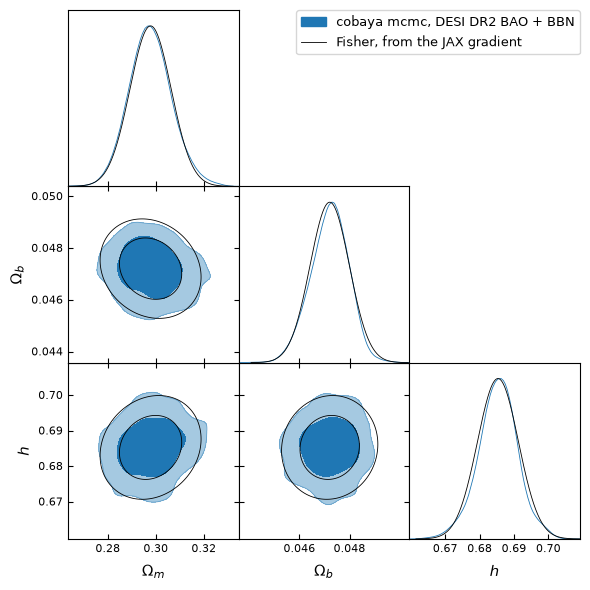

In [9]:
h = chain["H0"] / 100.0
chain.addDerived(h, name="h", label="h")
chain.addDerived(chain["ombh2"] / h ** 2, name="Omega_b", label=r"\Omega_b")
fisher = GaussianND(t0, cov_f, names=list(P), labels=[r"\Omega_m", r"\Omega_b", "h"], label="Fisher")
chain.updateSettings({"smooth_scale_2D": 0.4, "smooth_scale_1D": 0.4})
gplot = plots.get_subplot_plotter(width_inch=6.0)
gplot.triangle_plot([chain, fisher], list(P), filled=[True, False], contour_colors=["C0", "k"],
                    legend_labels=["cobaya mcmc, DESI DR2 BAO + BBN", "Fisher, from the JAX gradient"])
for p, s in zip(P, np.sqrt(np.diag(cov_f))):
    print(f"{p:8s} sigma: chain {chain.std(p):.4f}, Fisher {s:.4f}")
    assert abs(chain.std(p) / s - 1) < 0.1

The two agree to a few per cent, within the noise of the chain: in flat $\Lambda$CDM the BAO ratios are close to linear in the parameters over the width of the posterior, so the Gaussian approximation is close to exact.
The Fisher matrix costs one Jacobian, about a second; the chain costs a few thousand likelihood evaluations.

## The best fit

cobaya's `minimize` sampler finds the maximum of the posterior; it uses the same model, so either likelihood can be given to it.

In [10]:
_, mini = run(dict(info_jax, sampler={"minimize": {"ignore_prior": False}}, output=f"{out}/min", force=True))
best = mini.products()["minimum"]
print(f"best fit: H0 = {best['H0']:.3f}, ombh2 = {best['ombh2']:.5f}, omch2 = {best['omch2']:.5f}, "
      f"Omega_m = {best['Omega_m']:.4f}")
print(f"chi^2 at the best fit = {best['chi2']:.3f}")

[output] Output to be read-from/written-into folder '/tmp/tmp2nr7g9lc', with prefix 'min'


[minimize] Initializing


[minimize] Run 1/2 will start from random initial point:


[minimize] {'H0': np.float64(66.68294960966254), 'ombh2': np.float64(0.022325338686806365), 'omch2': np.float64(0.1196889781253855)}


[minimize] Run 2/2 will start from random initial point:


[minimize] {'H0': np.float64(67.85453346580624), 'ombh2': np.float64(0.022079364497556157), 'omch2': np.float64(0.12033431417162956)}


... (6 outputs left out)

[minimize] -log(posterior) minimized to -0.753984


[minimize] Parameter values at minimum:
   weight  minuslogpost         H0     ombh2     omch2   Omega_m       rdrag  minuslogprior  minuslogprior__0       chi2  chi2__desi_bao_jax
0     1.0     -0.753984  68.524896  0.022185  0.116721  0.297189  148.194751      -5.893464         -5.893464  10.278959           10.278959


[minimize] Full set of minima:
{'0': (-0.7539844827813527, True), '1': (-0.7538894157480902, True)}


best fit: H0 = 68.525, ombh2 = 0.02219, omch2 = 0.11672, Omega_m = 0.2972
chi^2 at the best fit = 10.279


## Exercises

1. Free $w_0$ and $w_a$: add `w` and `wa` to `PARAMS` with uniform priors, and compare the chain with the BAO + BBN forecast of Paper I, Sec. 4.1 (`tutorials/07_distance_constraints.ipynb`).
   Is the Fisher matrix still a good approximation?
2. Drop the BBN prior.
   Which combination of $H_0$ and $\omega_b$ is left constrained, and why?
3. Write the $w_p$ likelihood of {doc}`fit_wp` as a cobaya `Likelihood`, requesting `ggah_fields` from the theory at the sample's redshift, and sample it together with the BAO.